## Chart 1 win percentage

In [54]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import analysis

df = pd.read_csv("data/processed/IPL_Dataset_Cleaned.csv", low_memory=False)


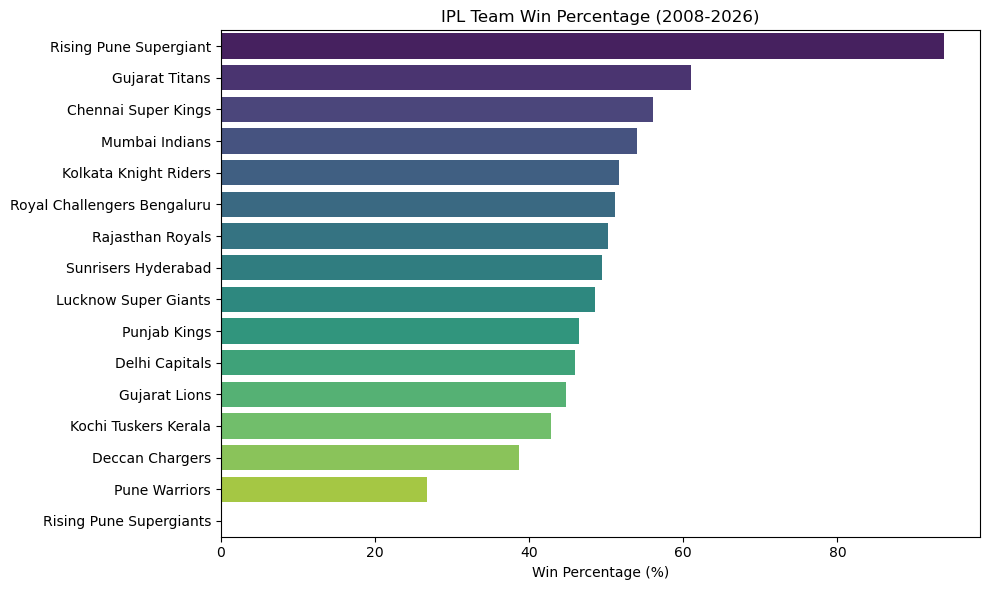

In [65]:
def plot_team_win_percentage(team_stats, save_path=None):
    plt.figure(figsize=(10,6))
    sns.barplot(data=team_stats, y='team', x='win_pct', hue='team', palette='viridis', legend=False)
    plt.xlabel('Win Percentage (%)')
    plt.ylabel('')
    plt.title('IPL Team Win Percentage (2008-2026)')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
        print(f"Saved to {save_path}")
    else:
        plt.show()




import importlib
import analysis
importlib.reload(analysis)
from analysis import compute_team_win_percentage
df = pd.read_csv("data/processed/IPL_Dataset_Cleaned.csv", low_memory=False)
team_stats = compute_team_win_percentage(df)
plot_team_win_percentage(team_stats)

### How has each team's performance trended season by season?

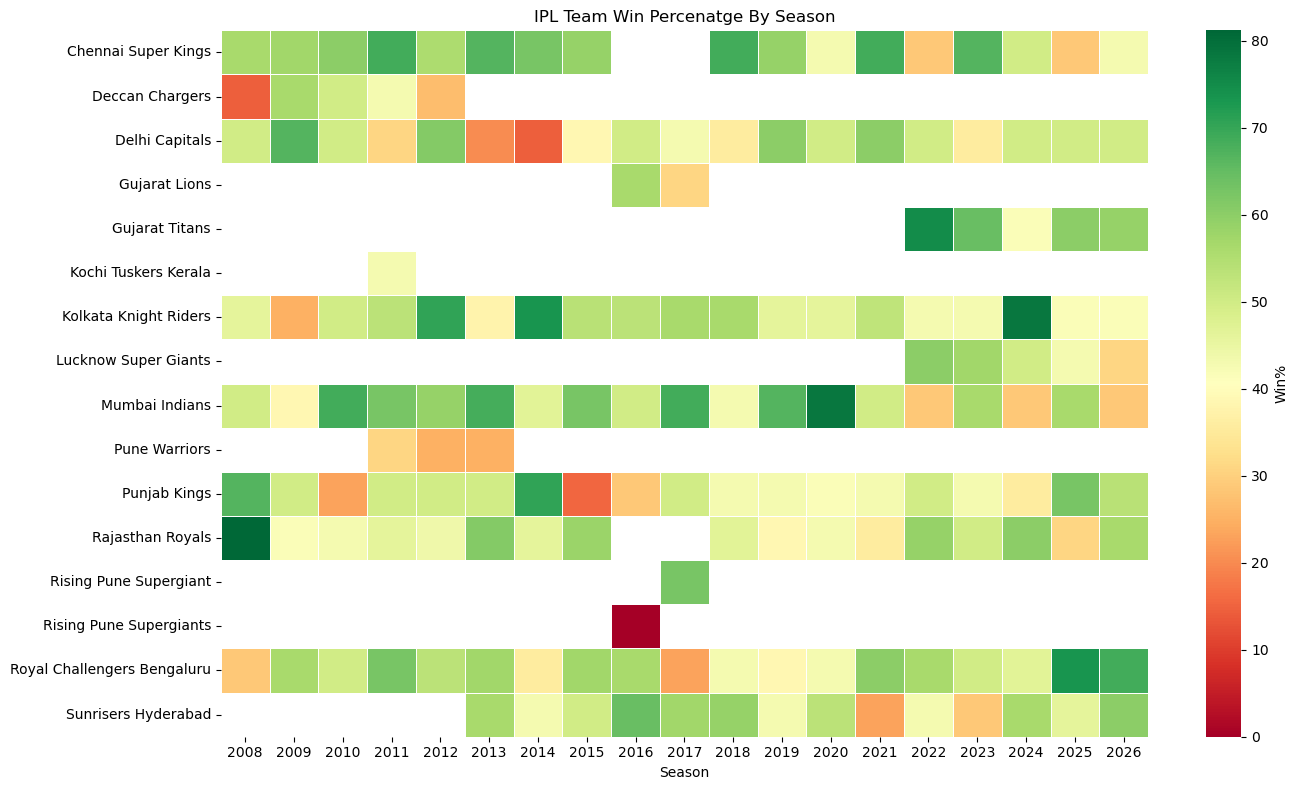

In [66]:
def plot_team_win_percentage_by_season(pivot, save_path = None):
    plt.figure(figsize=(14, 8))
    sns.heatmap(pivot, cmap='RdYlGn', linewidths = 0.5, linecolor='white', cbar_kws={'label':'Win%'})
    plt.xlabel('Season')
    plt.ylabel('')
    plt.title('IPL Team Win Percenatge By Season')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    else:
        plt.show()
        
import importlib
import analysis
importlib.reload(analysis)
from analysis import compute_team_win_percentage_by_season
season_pivot= compute_team_win_percentage_by_season(df)
plot_team_win_percentage_by_season(season_pivot)
    

## chart 3 - head to head win


Head-to-head: which teams dominate which opponents?

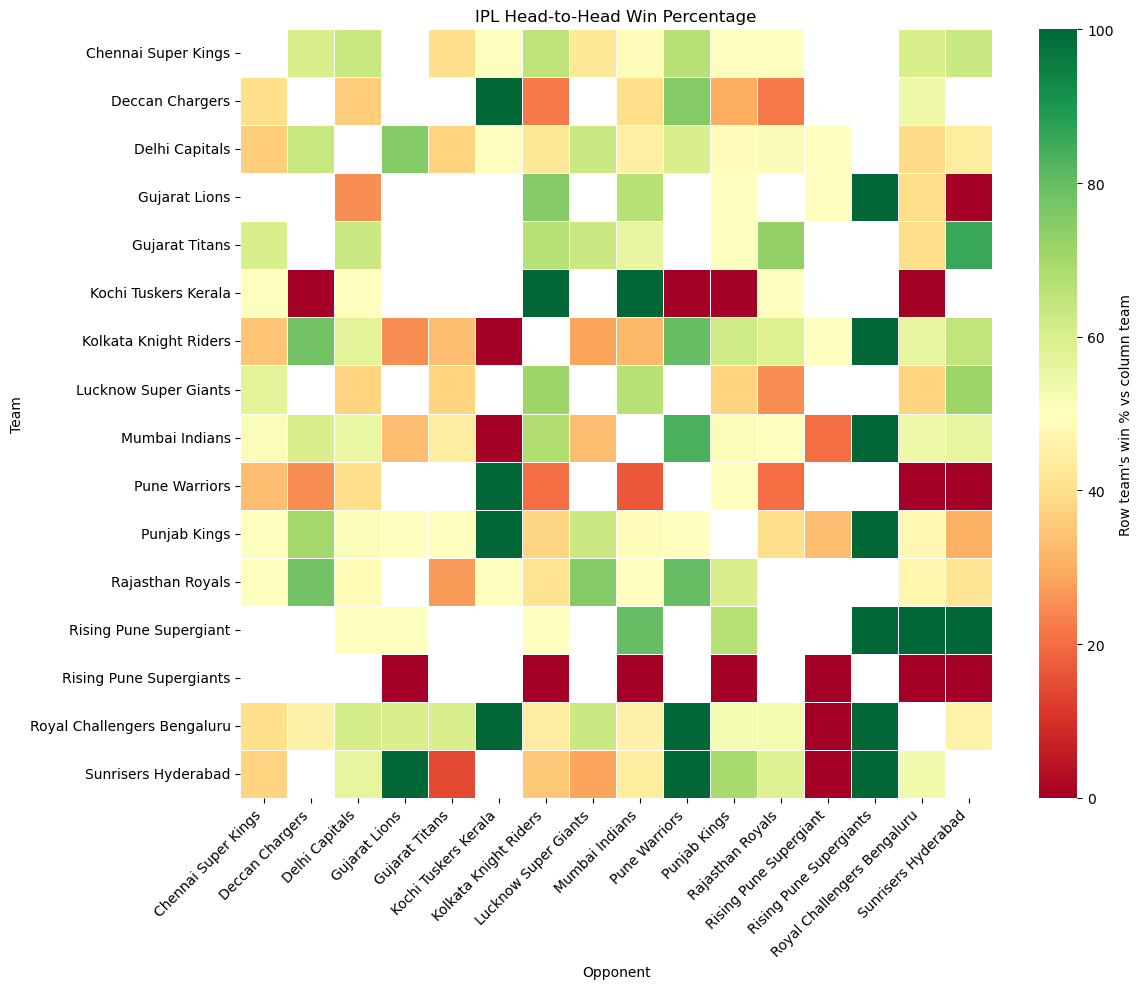

In [67]:
def plot_head_to_head(h2h_pivot, save_path=None):
    plt.figure(figsize=(12, 10))
    sns.heatmap(h2h_pivot, cmap='RdYlGn', center=50, linewidths=0.5, linecolor='white',
                cbar_kws={'label': "Row team's win % vs column team"})
    plt.xlabel('Opponent')
    plt.ylabel('Team')
    plt.title('IPL Head-to-Head Win Percentage')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    else:
        plt.show()




import importlib
import analysis
importlib.reload(analysis)
from analysis import compute_head_to_head
h2h_pivot = compute_head_to_head(df)
plot_head_to_head(h2h_pivot)

## Who are the all-time top run-scorers?

E:\neha work\Data Analytics\Projects\IPL sales analaysis\analysis.py:117: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.


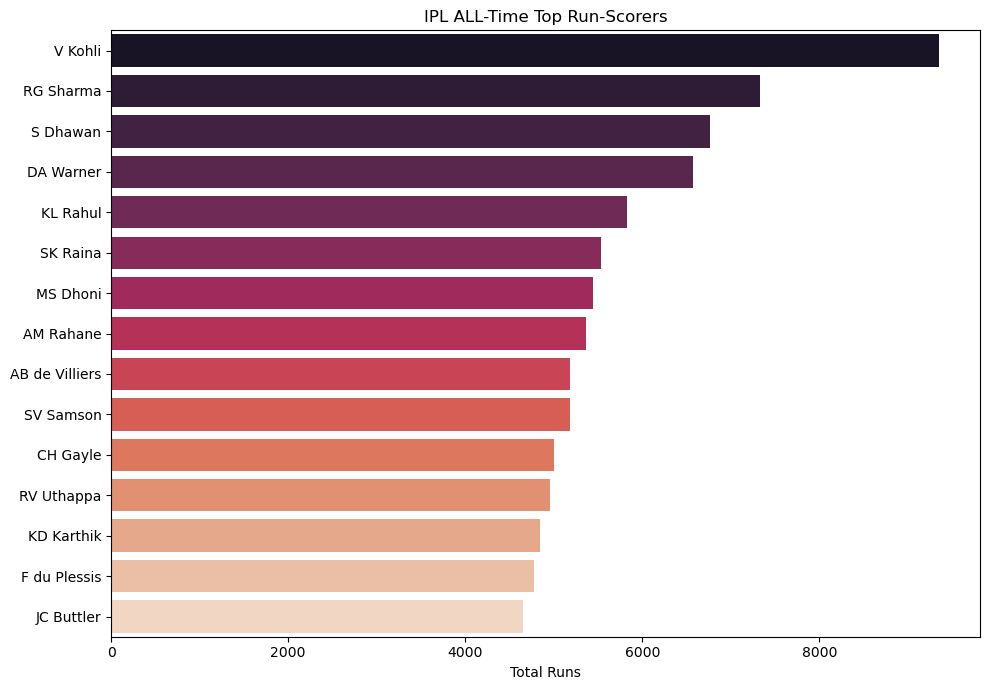

In [68]:
def plot_top_run_scorers(top_scorers, save_path=None):
    plt.figure(figsize=(10,7))
    data = top_scorers.reset_index()
    sns.barplot(data=data, y='batter',x='total_runs', hue='batter', palette='rocket', legend=False)
    plt.xlabel('Total Runs')
    plt.ylabel('')
    plt.title('IPL ALL-Time Top Run-Scorers')
    plt.tight_layout()
    if save_path:
       plt.savefig(save_path, dpi=150)
    else:
       plt.show()




import importlib
import analysis
importlib.reload(analysis)
from analysis import compute_top_run_scorers

top_scorers = compute_top_run_scorers(df)
plot_top_run_scorers(top_scorers)   

## chart 4

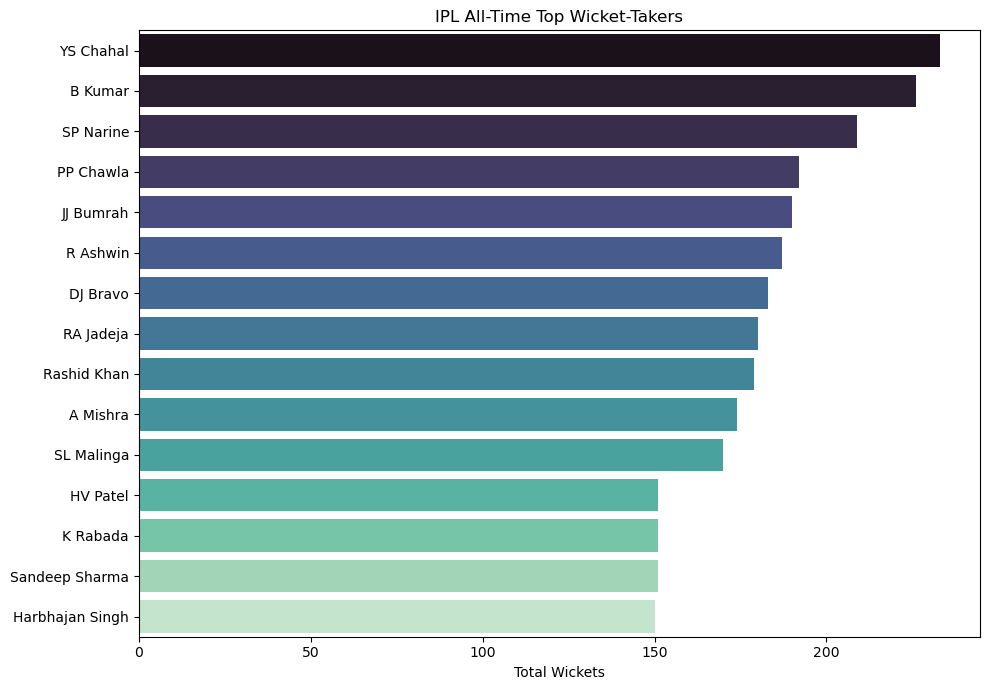

In [60]:
def plot_top_wicket_takers(top_bowlers, save_path=None):
    plt.figure(figsize=(10, 7))
    data = top_bowlers.reset_index()
    sns.barplot(data=data, y='bowler', x='total_wickets', hue='bowler', palette='mako', legend=False)
    plt.xlabel('Total Wickets')
    plt.ylabel('')
    plt.title('IPL All-Time Top Wicket-Takers')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    else:
        plt.show()


from analysis import compute_top_wicket_takers

top_bowlers = compute_top_wicket_takers(df)
plot_top_wicket_takers(top_bowlers)

## chart 5


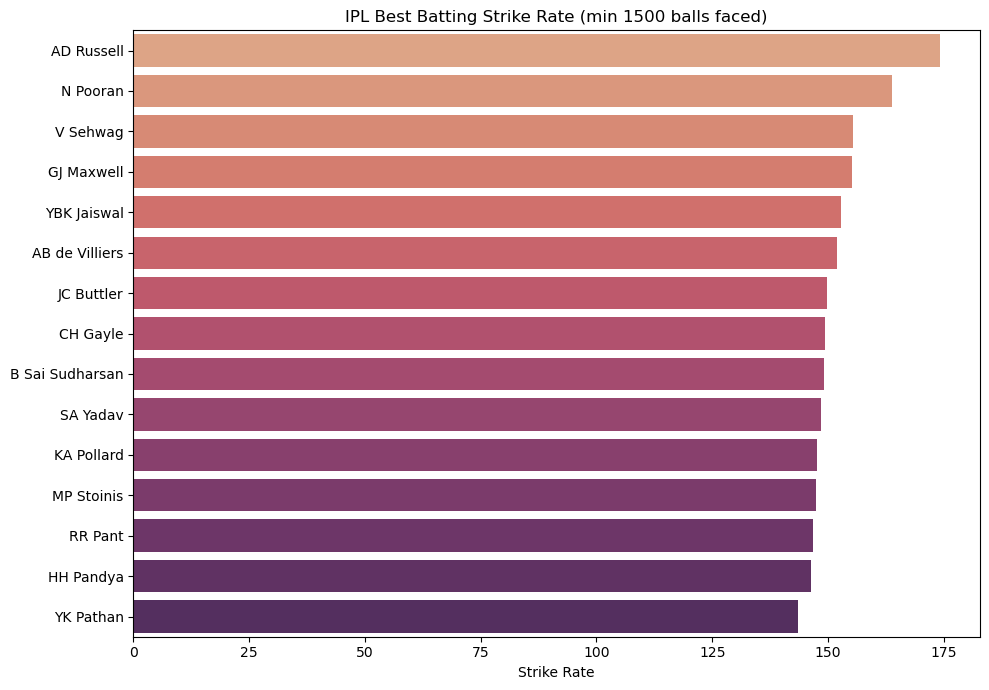

In [61]:
import pandas as pd
def plot_top_strike_rates(sr_df, save_path=None):
    plt.figure(figsize=(10, 7))
    data = sr_df.reset_index()
    sns.barplot(data=data, y='batter', x='strike_rate', hue='batter', palette='flare', legend=False)
    plt.xlabel('Strike Rate')
    plt.ylabel('')
    plt.title('IPL Best Batting Strike Rate (min 1500 balls faced)')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    else:
        plt.show()

import importlib
import analysis
importlib.reload(analysis)
from analysis import compute_top_strike_rates

sr_df = compute_top_strike_rates(df)
plot_top_strike_rates(sr_df)

In [62]:
## chart 6

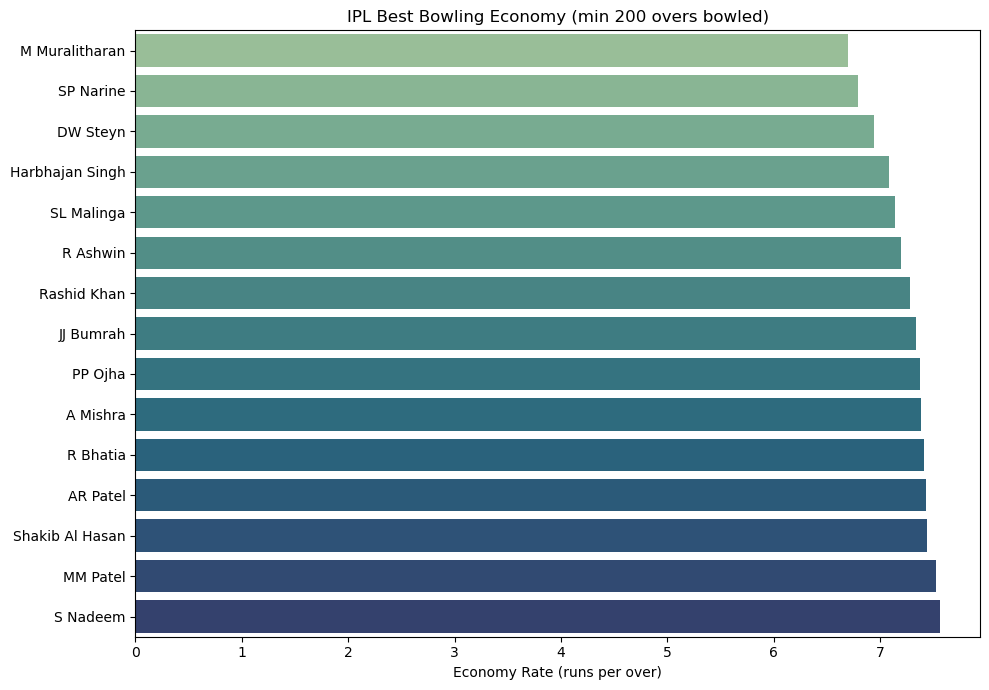

In [49]:
def plot_top_economy_bowlers(eco_df, save_path=None):
    plt.figure(figsize=(10, 7))
    data = eco_df.reset_index()
    sns.barplot(data=data, y='bowler', x='economy', hue='bowler', palette='crest', legend=False)
    plt.xlabel('Economy Rate (runs per over)')
    plt.ylabel('')
    plt.title('IPL Best Bowling Economy (min 200 overs bowled)')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    else:
        plt.show()

import importlib
import analysis
importlib.reload(analysis)
from analysis import compute_top_economy_bowlers

eco_df = compute_top_economy_bowlers(df)
plot_top_economy_bowlers(eco_df)

### chart 8

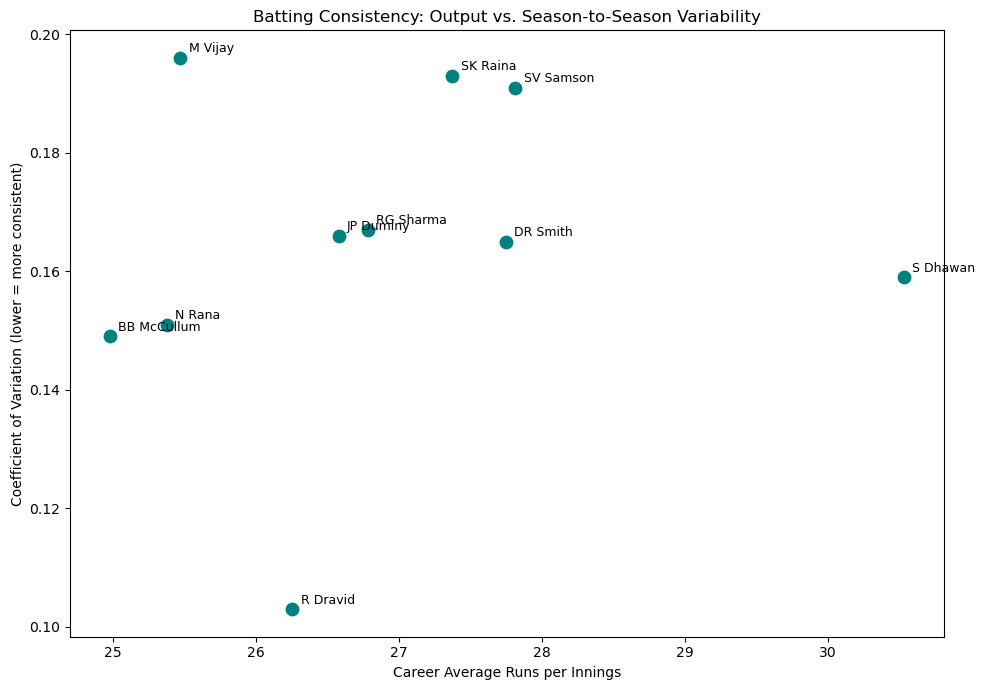

In [63]:
def plot_batting_consistency(consistency_df, save_path=None):
    plt.figure(figsize=(10, 7))
    data = consistency_df.reset_index()
    plt.scatter(data['career_avg_runs'], data['cv'], s=80, color='teal')
    for _, row in data.iterrows():
        plt.annotate(row['batter'], (row['career_avg_runs'], row['cv']), textcoords="offset points", xytext=(6, 4), fontsize=9)
    plt.xlabel('Career Average Runs per Innings')
    plt.ylabel('Coefficient of Variation (lower = more consistent)')
    plt.title('Batting Consistency: Output vs. Season-to-Season Variability')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    else:
        plt.show()

import importlib
import analysis
importlib.reload(analysis)
from analysis import compute_batting_consistency

consistency_df = compute_batting_consistency(df)
plot_batting_consistency(consistency_df)

## chrat 9

Overall: 51.6 %
toss_decision
bat      45.3
field    54.7
Name: toss_winner_won_match, dtype: float64


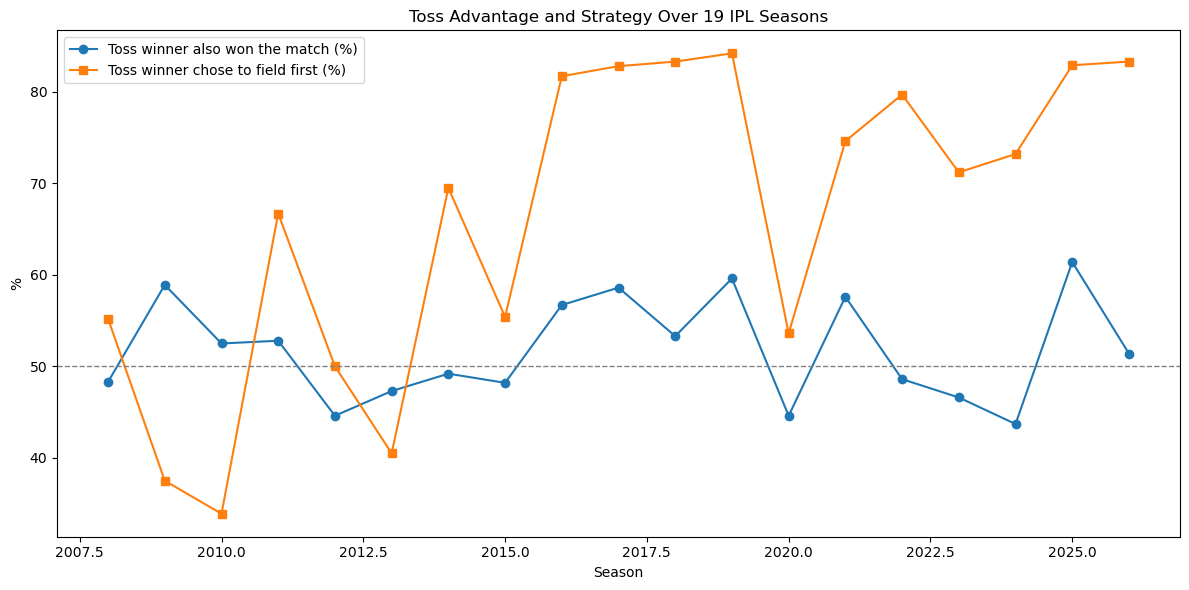

In [64]:
def plot_toss_trends(by_season, save_path=None):
    plt.figure(figsize=(12, 6))
    plt.plot(by_season.index, by_season['toss_win_match_pct'], marker='o', label='Toss winner also won the match (%)')
    plt.plot(by_season.index, by_season['field_first_pct'], marker='s', label='Toss winner chose to field first (%)')
    plt.axhline(50, color='grey', linestyle='--', linewidth=1)
    plt.xlabel('Season')
    plt.ylabel('%')
    plt.title('Toss Advantage and Strategy Over 19 IPL Seasons')
    plt.legend()
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    else:
        plt.show()

import importlib
import analysis
importlib.reload(analysis)
from analysis import compute_toss_match_correlation

overall_pct, by_decision, by_season = compute_toss_match_correlation(df)
print("Overall:", overall_pct, "%")
print(by_decision)
plot_toss_trends(by_season)

## Chart 10 

Overall chase win rate: 54.3 %


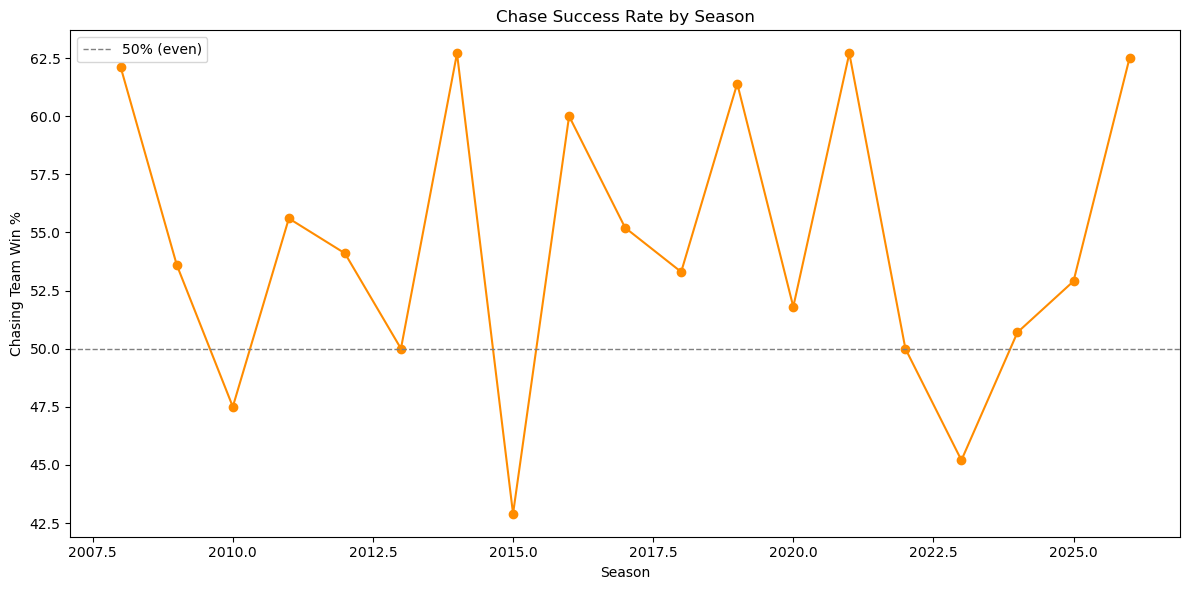

In [69]:
def plot_chase_win_rate(by_season, save_path=None):
    plt.figure(figsize=(12, 6))
    plt.plot(by_season.index, by_season.values, marker='o', color='darkorange')
    plt.axhline(50, color='grey', linestyle='--', linewidth=1, label='50% (even)')
    plt.xlabel('Season')
    plt.ylabel('Chasing Team Win %')
    plt.title('Chase Success Rate by Season')
    plt.legend()
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    else:
        plt.show()

import importlib
import analysis
importlib.reload(analysis)
from analysis import compute_chase_vs_defend

overall_pct, by_season = compute_chase_vs_defend(df)
print("Overall chase win rate:", overall_pct, "%")
plot_chase_win_rate(by_season)

## chart 11 - Which venues produce the highest/lowest average first-innings scores?

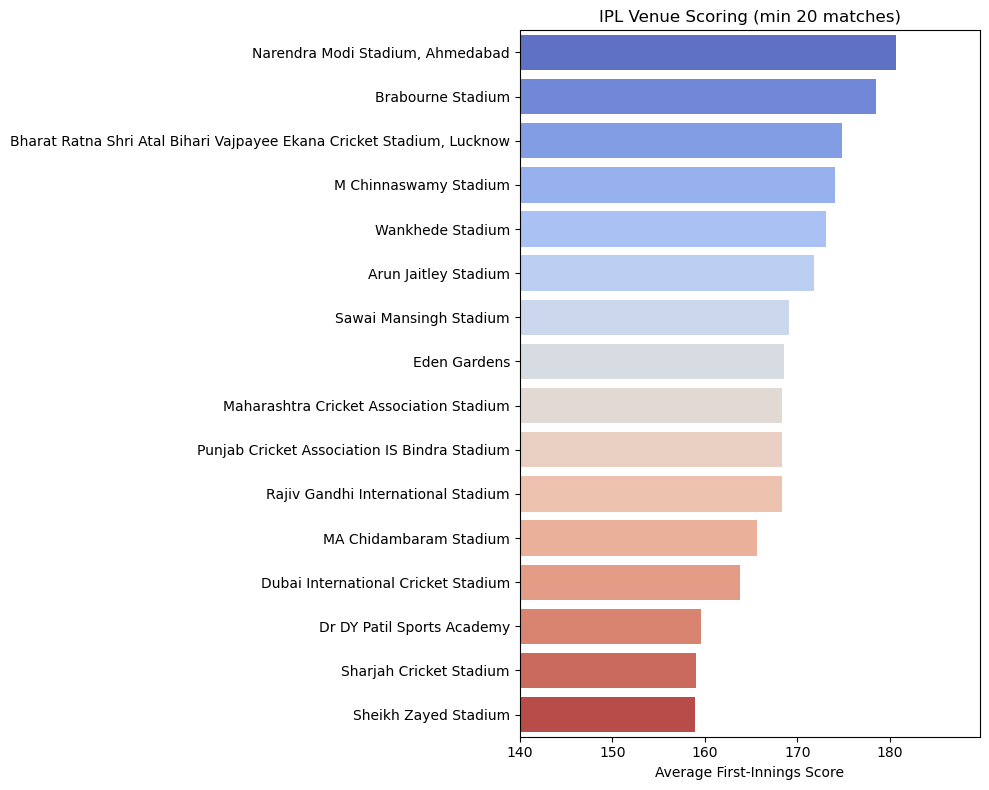

In [70]:
def plot_venue_scoring(venue_scores, save_path=None):
    plt.figure(figsize=(10, 8))
    data = venue_scores.reset_index()
    sns.barplot(data=data, y='venue', x='avg_first_innings_score', hue='venue', palette='coolwarm', legend=False)
    plt.xlabel('Average First-Innings Score')
    plt.ylabel('')
    plt.title('IPL Venue Scoring (min 20 matches)')
    plt.xlim(140, None)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    else:
        plt.show()

import importlib
import analysis
importlib.reload(analysis)
from analysis import compute_venue_scoring

venue_scores = compute_venue_scoring(df)
plot_venue_scoring(venue_scores)

## chart 12- What do the biggest winning margins look like?

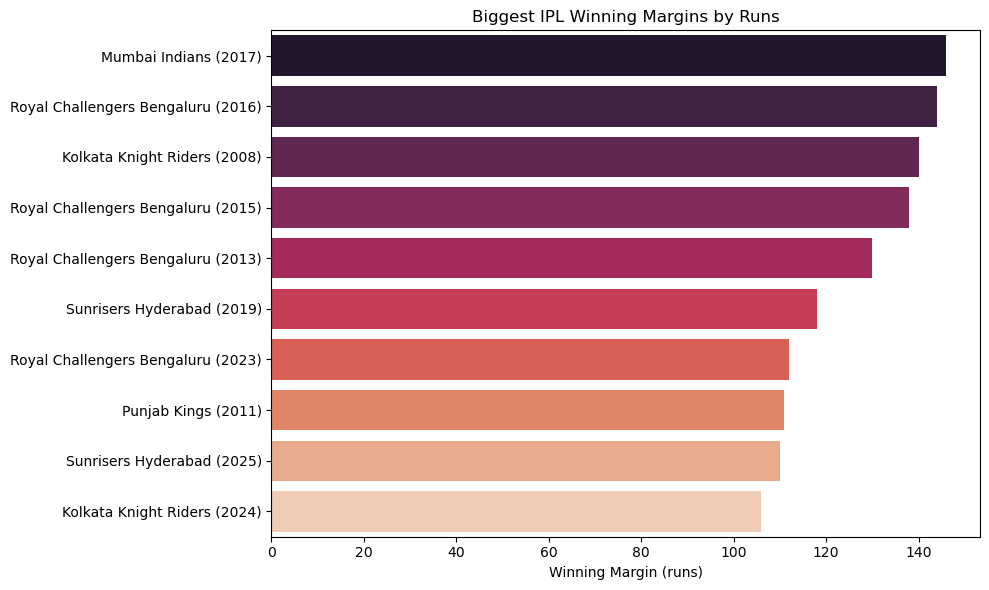

In [74]:
def plot_biggest_runs_margins(biggest_runs, save_path=None):
    plt.figure(figsize=(10, 6))
    data = biggest_runs.copy()
    data['label'] = data['won_by'] + ' (' + data['season'].astype(str) + ')'
    sns.barplot(data=data, y='label', x='win_margin', hue='label', palette='rocket', legend=False)
    plt.xlabel('Winning Margin (runs)')
    plt.ylabel('')
    plt.title('Biggest IPL Winning Margins by Runs')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    else:
        plt.show()

import importlib
import analysis
importlib.reload(analysis)
from analysis import compute_biggest_margins

biggest_runs, biggest_wickets, closest = compute_biggest_margins(df)

plot_biggest_runs_margins(biggest_runs)